# MEMC exercise 3 – Discrete distributions

---

So far we have taken generators ready-made (`random.random()`, `random.gauss()`). Now we learn to
**build our own**. We start with discrete distributions, because they are the simplest and their
idea comes back everywhere:

> Out of a single uniform number $\gamma \in [0, 1)$ we build an arbitrary random variable by cutting
> $[0, 1)$ into pieces and looking at which piece $\gamma$ fell into.

In this notebook you see:

- the **basic (linear) algorithm** and its cost
- how to speed it up by **reordering** the probabilities
- **bisection** over the cumulative sums
- the **Poisson distribution** and a nice bug that creeps into it easily
- the geometric distribution (we met it in exercise 2)

In [1]:
import math
import random
import time
from bisect import bisect_right
from itertools import accumulate

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def estimate(sampler, n):
    '''Plain Monte Carlo: the average of n calls of the generator and its standard error sigma/sqrt(n).'''
    s = s2 = 0.0
    for _ in range(n):
        x = sampler()
        s += x
        s2 += x * x
    mean = s / n
    var = max(s2 / n - mean * mean, 0.0)
    return mean, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    '''Prints the estimate and verifies it lies within k standard errors of the exact value.'''
    print(f"{name}: {mean:.5f} +- {se:.5f}  (exact {exact:.5f})")
    assert abs(mean - exact) <= k * se, name

## 1. The basic algorithm

We have a discrete variable with values $0, 1, \dots, n-1$ and probabilities $p_0, \dots, p_{n-1}$
(summing to $1$). We cut the interval $[0, 1)$ into segments of lengths $p_0, p_1, \dots$:

$$[0, p_0),\ [p_0, p_0 + p_1),\ [p_0 + p_1, p_0 + p_1 + p_2),\ \dots$$

A uniform $\gamma$ falls into segment $k$ with a probability equal to its length, i.e. exactly $p_k$.
The result is the index $k$ of the segment that $\gamma$ fell into.

**The algorithm:** $S \leftarrow \gamma$; for $k = 0, 1, \dots$ subtract $S \leftarrow S - p_k$; as
soon as $S < 0$, return $k$.

This is the **inverse transform** in the discrete case: we look for the smallest $k$ with
$\gamma < F(k) = p_0 + \dots + p_k$.

A picture of the algorithm: on the left the interval $[0, 1)$ cut into segments of lengths $p_k$ and
three sample values of $\gamma$ (the arrows) with the values that come out of them. On the right the
same thing as a **step distribution function**: plot $\gamma$ on the vertical axis, go right to the
first step and read $k$ off below.

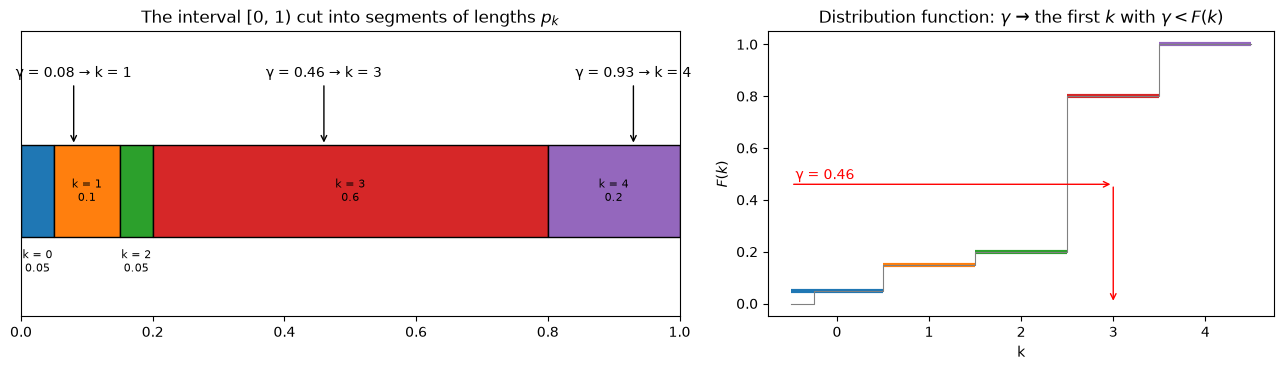

In [2]:
p_demo = [0.05, 0.1, 0.05, 0.6, 0.2]
cum_demo = [sum(p_demo[:k + 1]) for k in range(len(p_demo))]
colors = plt.cm.tab10.colors
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})

ax = axes[0]
start = 0.0
for k, pk in enumerate(p_demo):
    ax.barh(0, pk, left=start, color=colors[k], edgecolor="k")
    label = f"k = {k}\n{pk:g}"
    if pk >= 0.1:
        ax.text(start + pk / 2, 0, label, ha="center", va="center", fontsize=8)
    else:
        ax.text(start + pk / 2, -0.5, label, ha="center", va="top", fontsize=8)
    start += pk
for u in (0.08, 0.46, 0.93):
    k = next(i for i, c in enumerate(cum_demo) if u < c)
    ax.annotate(f"γ = {u} → k = {k}", xy=(u, 0.4), xytext=(u, 1.0), ha="center", arrowprops=dict(arrowstyle="->"))
ax.set_ylim(-1.1, 1.4)
ax.set_xlim(0, 1)
ax.set_yticks([])
ax.set_title("The interval [0, 1) cut into segments of lengths $p_k$")

ax = axes[1]
for k in range(len(p_demo)):
    ax.hlines(cum_demo[k], k - 0.5, k + 0.5, color=colors[k], lw=3)
ax.step([-0.5] + list(range(len(p_demo))) + [len(p_demo) - 0.5], [0] + cum_demo + [1], where="mid", color="gray", lw=0.8)
u = 0.46
k = next(i for i, c in enumerate(cum_demo) if u < c)
ax.annotate("", xy=(k, u), xytext=(-0.5, u), arrowprops=dict(arrowstyle="->", color="r"))
ax.annotate("", xy=(k, 0), xytext=(k, u), arrowprops=dict(arrowstyle="->", color="r"))
ax.text(-0.45, u + 0.02, "γ = 0.46", color="r")
ax.set_xticks(range(len(p_demo)))
ax.set_xlabel("k")
ax.set_ylabel("$F(k)$")
ax.set_title("Distribution function: $\\gamma$ → the first $k$ with $\\gamma < F(k)$")
plt.tight_layout()
plt.show()

E X (linear): 2.80214 +- 0.00230  (exact 2.80000)


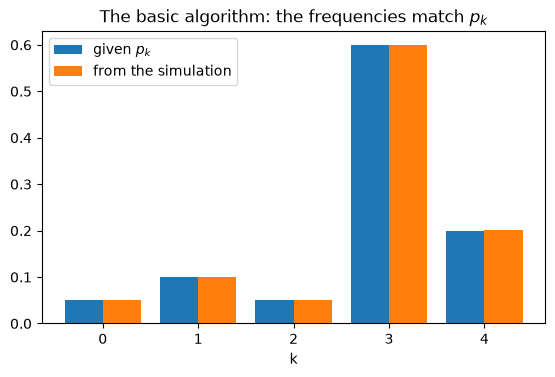

In [3]:
def linear(p):
    '''The basic algorithm: S = γ; subtract p_k until S < 0. Returns (index, number of steps).'''
    s = random.random()
    for k, pk in enumerate(p):
        s -= pk
        if s < 0:
            return k, k + 1
    return len(p) - 1, len(p)  # a safeguard against rounding, in case sum(p) is a hair under 1


p = [0.05, 0.1, 0.05, 0.6, 0.2]
values = [0, 1, 2, 3, 4]
exact_mean = sum(v * q for v, q in zip(values, p))

n = 200_000
m, se = estimate(lambda: linear(p)[0], n)
check("E X (linear)", m, se, exact_mean)

# frequencies from the simulation vs. the given probabilities
counts = [0] * len(p)
for _ in range(n):
    counts[linear(p)[0]] += 1

x = range(len(p))
plt.figure(figsize=(6.5, 3.8))
plt.bar([i - 0.2 for i in x], p, width=0.4, label="given $p_k$")
plt.bar([i + 0.2 for i in x], [c / n for c in counts], width=0.4, label="from the simulation")
plt.xlabel("k")
plt.title("The basic algorithm: the frequencies match $p_k$")
plt.legend()
plt.show()

### A special case: the Bernoulli variable

For two values $\{0, 1\}$ with $P(X = 1) = q$ the algorithm collapses to a single comparison:

In [4]:
def bernoulli(q):
    '''1 with probability q, otherwise 0.'''
    return 1 if random.random() < q else 0


m, se = estimate(lambda: bernoulli(0.3), n)
check("Bernoulli(0.3)", m, se, 0.3)

Bernoulli(0.3): 0.30129 +- 0.00103  (exact 0.30000)


## 2. What does it cost? Reordering

The number of steps of the algorithm is $k + 1$ when the value $k$ comes out. So the mean number of
steps is

$$E[\text{steps}] = \sum_k (k+1)\,p_k.$$

The order of the values is **ours to choose** (it is only our labelling), and that is why it pays to
sort them **descending by probability**: the most probable values are then found right at the start.
The result (which value we return) does not change, we only have to map the index back to the
original value at the end.

How the order changes the cost can be seen on a small example: the values are segments of the unit
interval and the algorithm walks through them **left to right** until $\gamma$ finds its segment. The
number inside a segment is the number of steps taken when $\gamma$ falls into it. Large segments up
front are hit immediately, which is why descending order is the cheapest.

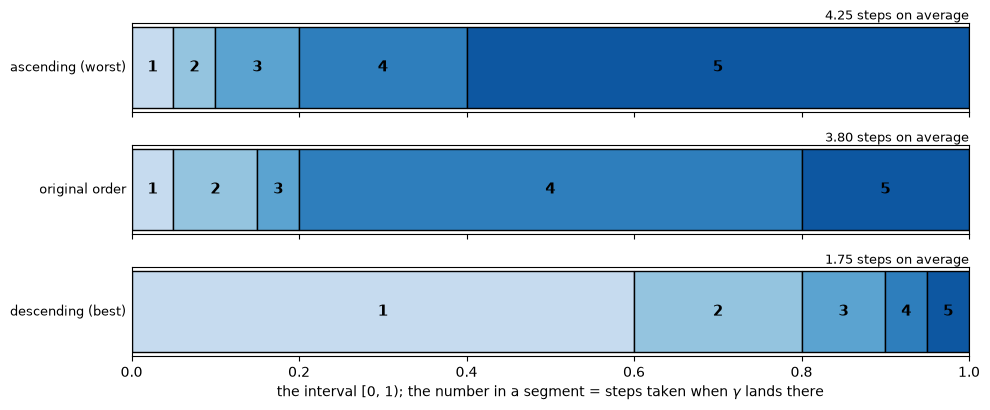

In [5]:
p_example = [0.05, 0.1, 0.05, 0.6, 0.2]
variants = {
    "ascending (worst)": sorted(p_example),
    "original order": p_example,
    "descending (best)": sorted(p_example, reverse=True),
}
fig, axes = plt.subplots(len(variants), 1, figsize=(10, 4.2), sharex=True)
for ax, (name, pp) in zip(axes, variants.items()):
    start = 0.0
    for j, pk in enumerate(pp):
        ax.barh(0, pk, left=start, color=plt.cm.Blues(0.25 + 0.15 * j), edgecolor="k")
        ax.text(start + pk / 2, 0, f"{j + 1}", ha="center", va="center", fontsize=11, fontweight="bold")
        start += pk
    steps_ = sum((j + 1) * pk for j, pk in enumerate(pp))
    ax.set_yticks([])
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
    ax.set_title(f"{steps_:.2f} steps on average", fontsize=9, loc="right", pad=2)
axes[-1].set_xlim(0, 1)
axes[-1].set_xlabel("the interval [0, 1); the number in a segment = steps taken when $\\gamma$ lands there")
plt.tight_layout()
plt.show()

In [6]:
def make_reordered(p):
    '''Visits the values starting from the most probable one. Returns (original index, number of steps).'''
    order = sorted(range(len(p)), key=lambda i: -p[i])
    p_sorted = [p[i] for i in order]

    def sample():
        k, steps = linear(p_sorted)
        return order[k], steps

    return sample


steps_original = sum((k + 1) * q for k, q in enumerate(p))
p_sorted_desc = sorted(p, reverse=True)
steps_sorted = sum((k + 1) * q for k, q in enumerate(p_sorted_desc))
print(f"mean number of steps, original order:    {steps_original:.2f}")
print(f"mean number of steps, descending order:  {steps_sorted:.2f}")

m, se = estimate(lambda: linear(p)[1], n)
check("steps, original order", m, se, steps_original)

reordered = make_reordered(p)
m, se = estimate(lambda: reordered()[1], n)
check("steps, descending order", m, se, steps_sorted)

# the result has not changed, only the cost
m, se = estimate(lambda: reordered()[0], n)
check("E X (reordered)", m, se, exact_mean)

mean number of steps, original order:    3.80
mean number of steps, descending order:  1.75
steps, original order: 3.80119 +- 0.00231  (exact 3.80000)


steps, descending order: 1.74797 +- 0.00253  (exact 1.75000)
E X (reordered): 2.79938 +- 0.00230  (exact 2.80000)


## 3. Bisection

Subtracting is linear in the number of values. When there are many values (hundreds, thousands), it
pays to precompute the **cumulative sums** $F_k = p_0 + \dots + p_k$ (an increasing sequence) and to
look for the smallest $k$ with $\gamma < F_k$ **by bisection**:

- precomputation: $O(n)$, once
- each draw: $O(\log n)$

The invariant: the $k$ we are looking for always lies in $[\text{lo}, \text{hi}]$; a comparison with
the midpoint halves the interval.

The course of it on an example with $16$ values (the probabilities grow with $k$): on the left the
distribution function with the **comparisons** marked, on the right the **shrinking interval**
$[\text{lo}, \text{hi}]$ step by step. After every comparison the interval halves, so after
$\lceil\log_2 16\rceil = 4$ steps a single value is left.

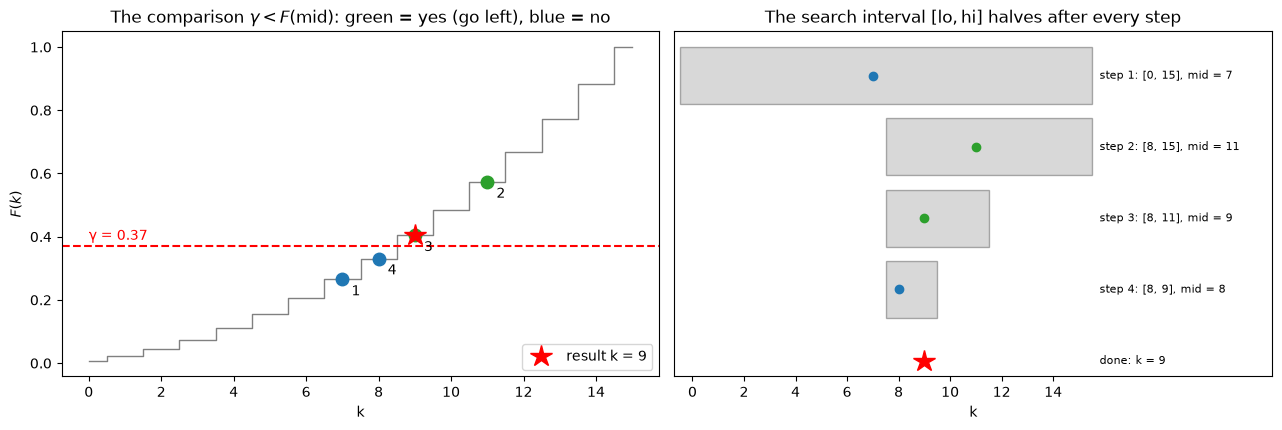

In [7]:
nb_ = 16
w16 = [k + 1 for k in range(nb_)]
p16 = [x / sum(w16) for x in w16]
cum16 = list(accumulate(p16))
g16 = 0.37

lo, hi = 0, nb_ - 1
steps_b = []
while lo < hi:
    mid = (lo + hi) // 2
    left = g16 < cum16[mid]
    steps_b.append((lo, hi, mid, left))
    if left:
        hi = mid
    else:
        lo = mid + 1
result_k = lo

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
ax.step(range(nb_), cum16, where="mid", color="gray", lw=1)
ax.axhline(g16, color="r", ls="--")
ax.text(0, g16 + 0.02, f"γ = {g16}", color="r")
for i, (lo_, hi_, mid_, left) in enumerate(steps_b, 1):
    ax.plot([mid_], [cum16[mid_]], "o", color="tab:green" if left else "tab:blue", ms=9)
    ax.text(mid_ + 0.25, cum16[mid_] - 0.05, f"{i}", fontsize=10)
ax.plot([result_k], [cum16[result_k]], "*", color="r", ms=16, label=f"result k = {result_k}")
ax.set_xlabel("k")
ax.set_ylabel("$F(k)$")
ax.set_title("The comparison $\\gamma < F(\\mathrm{mid})$: green = yes (go left), blue = no")
ax.legend(loc="lower right")

ax = axes[1]
for i, (lo_, hi_, mid_, left) in enumerate(steps_b):
    ax.barh(-i, hi_ - lo_ + 1, left=lo_ - 0.5, color="tab:gray", alpha=0.3, edgecolor="k")
    ax.plot([mid_], [-i], "o", color="tab:green" if left else "tab:blue")
    ax.text(nb_ - 0.2, -i, f"step {i + 1}: [{lo_}, {hi_}], mid = {mid_}", va="center", fontsize=8)
ax.plot([result_k], [-len(steps_b)], "*", color="r", ms=16)
ax.text(nb_ - 0.2, -len(steps_b), f"done: k = {result_k}", va="center", fontsize=8)
ax.set_xlim(-0.7, nb_ + 6.5)
ax.set_xticks(range(0, nb_, 2))
ax.set_yticks([])
ax.set_xlabel("k")
ax.set_title("The search interval $[\\mathrm{lo}, \\mathrm{hi}]$ halves after every step")
plt.tight_layout()
plt.show()

In [8]:
def make_bisect(p):
    '''We precompute the cumulative sums once; each draw then costs O(log n).'''
    cum, total = [], 0.0
    for pk in p:  # the library equivalent: list(itertools.accumulate(p))
        total += pk
        cum.append(total)

    def sample():
        gamma = random.random()
        # the library equivalent: bisect.bisect_right(cum, gamma)
        lo, hi = 0, len(cum) - 1   # hi is also a rescue in case cum[-1] < 1 due to rounding
        while lo < hi:
            mid = (lo + hi) // 2
            if gamma < cum[mid]:
                hi = mid
            else:
                lo = mid + 1
        return lo

    return sample


def make_bisect_lib(p):
    '''The same thing, from the standard library.'''
    cum = list(accumulate(p))
    return lambda: min(bisect_right(cum, random.random()), len(p) - 1)


m, se = estimate(make_bisect(p), n)
check("E X (bisect)", m, se, exact_mean)
m, se = estimate(make_bisect_lib(p), n)
check("E X (bisect, stdlib)", m, se, exact_mean)

E X (bisect): 2.79567 +- 0.00231  (exact 2.80000)


E X (bisect, stdlib): 2.79835 +- 0.00231  (exact 2.80000)


## 4. Which method is best, and when?

We try it on a distribution with $1000$ values, $p_k \propto 1/(k+1)^2$ (a few values carry a large
probability, a long tail holds the rest). We compare four variants:

1. linear, values sorted **ascending** by probability (the worst order),
2. linear, values in a **random order**: the neutral case, when we do not think about the order at
   all (in practice the natural order of the values, for instance $0, 1, 2, \dots$, tends to be
   exactly this "random" with respect to the probabilities; whether it comes out better or worse
   depends on the shape of the distribution),
3. linear, values sorted **descending** (the best order),
4. bisection.

One particular random permutation can be lucky or unlucky (it depends where the most probable value
lands), which is why for the random order we **average over a hundred permutations**. On average
every value is equally likely to be in every position, so the mean number of steps comes out as
$(n+1)/2$ regardless of the shape of the distribution.

In [9]:
nvals = 1000
w = [1 / (k + 1) ** 2 for k in range(nvals)]
total = sum(w)
p_desc = [x / total for x in w]           # descending: the most probable first
p_asc = p_desc[::-1]                      # ascending: the worst order for a linear search

draws = 20_000
results = []

def measure(name, sampler):
    t0 = time.perf_counter()
    steps, _ = estimate(sampler, draws)
    t = (time.perf_counter() - t0) / draws
    results.append((name, steps, t))


measure("linear, ascending", lambda: linear(p_asc)[1])

# random order: 100 different permutations of 200 draws each (one permutation can be lucky or unlucky)
steps_perm = []
t0 = time.perf_counter()
for _ in range(100):
    p_rand = p_desc[:]
    random.shuffle(p_rand)
    steps_perm.append(estimate(lambda: linear(p_rand)[1], draws // 100)[0])
t_rand = (time.perf_counter() - t0) / draws
results.append(("linear, random", sum(steps_perm) / len(steps_perm), t_rand))

measure("linear, descending", lambda: linear(p_desc)[1])

bis = make_bisect(p_asc)
t0 = time.perf_counter()
for _ in range(draws):
    bis()
t = (time.perf_counter() - t0) / draws
results.append(("bisection", math.ceil(math.log2(nvals)), t))

print(f"{'method':22s} {'steps per draw':>18s} {'time per draw':>17s}")
for name, steps, t in results:
    print(f"{name:22s} {steps:18.1f} {t * 1e6:14.1f} us")
print(f"\nrandom order: theory (n + 1) / 2 = {(nvals + 1) / 2:.1f}; "
      f"the individual permutations gave from {min(steps_perm):.0f} to {max(steps_perm):.0f} steps")

method                     steps per draw     time per draw
linear, ascending                   996.6           39.1 us
linear, random                      490.9           23.6 us
linear, descending                    4.8            0.4 us
bisection                            10.0            0.6 us

random order: theory (n + 1) / 2 = 500.5; the individual permutations gave from 133 to 798 steps


The same thing as a picture (the values from the table above):

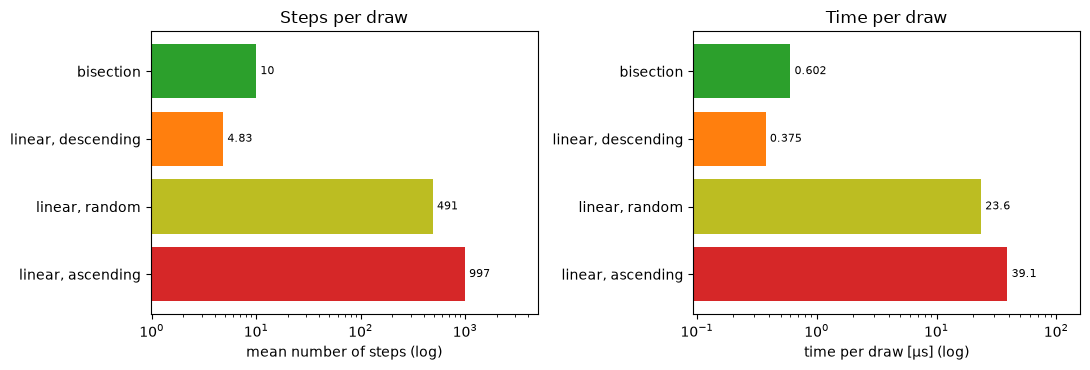

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
names = [v[0] for v in results]
colors_ = ["tab:red", "tab:olive", "tab:orange", "tab:green"]
b0 = axes[0].barh(names, [v[1] for v in results], color=colors_)
axes[0].set_xscale("log")
axes[0].bar_label(b0, fmt="%.3g", padding=3, fontsize=8)
axes[0].margins(x=0.3)
axes[0].set_xlabel("mean number of steps (log)")
axes[0].set_title("Steps per draw")
b1 = axes[1].barh(names, [v[2] * 1e6 for v in results], color=colors_)
axes[1].set_xscale("log")
axes[1].bar_label(b1, fmt="%.3g", padding=3, fontsize=8)
axes[1].margins(x=0.3)
axes[1].set_xlabel("time per draw [µs] (log)")
axes[1].set_title("Time per draw")
plt.tight_layout()
plt.show()

We can see that:

- **The order is crucial** for the linear algorithm: ascending order is many times worse than
  descending.
- **A random order** lies in between: $(n+1)/2$ steps on average, so only about twice as good as the
  worst case and an order of magnitude worse than descending. Anyone who does not think about the
  order gains nothing from a linear search.
- **Bisection does not depend on the order** and has a guaranteed $\lceil\log_2 n\rceil$ steps.
- For a very uneven distribution, **linear with a good order** can beat even bisection (the mean
  number of steps is small). For more even probabilities, bisection wins.

So the choice depends on the shape of the distribution: if you know it and it is markedly uneven,
sort and use linear; otherwise bisection.

## 5. The Poisson distribution

The Poisson distribution $P(X = k) = \dfrac{\lambda^k e^{-\lambda}}{k!}$ has **infinitely many**
values, so we cannot build the table of $p_k$ in advance. But there is an elegant algorithm.

### The derivation

The number of events of a Poisson process of intensity $1$ in the interval $[0, \lambda]$ has the
$\operatorname{Poisson}(\lambda)$ distribution. The gaps between events are independent exponentials
$E_i = -\ln \gamma_i$ (exercise 4). The number of events in $[0, \lambda]$ is therefore the largest
$k$ for which $E_1 + \dots + E_k \le \lambda$. This can be rewritten:

$$E_1 + \dots + E_{k} \le \lambda
\iff -\ln(\gamma_1 \cdots \gamma_k) \le \lambda
\iff \gamma_1 \gamma_2 \cdots \gamma_k \ge e^{-\lambda}.$$

**The algorithm:** multiply uniform numbers $\gamma_1, \gamma_2, \dots$ until the product drops below
$e^{-\lambda}$. If we needed $K$ numbers for that, the result is $K - 1$ (the last number
"overshot", so one fewer fitted into $[0, \lambda]$).

An illustration: each row is one trial. The dots are the event times $E_1,\ E_1 + E_2,\ \dots$ (the
partial sums of the exponential gaps) on a time axis. The value of the Poisson variable is the number
of dots that fit into $[0, \lambda]$ (here $\lambda = 4$, the vertical line).

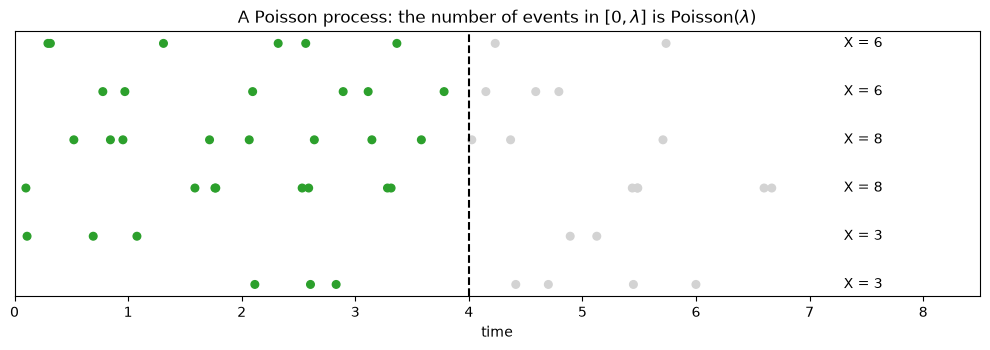

In [11]:
lam_demo = 4.0
fig, ax = plt.subplots(figsize=(10, 3.6))
for row in range(6):
    t, pts = 0.0, []
    while t <= lam_demo + 3:
        t += -math.log(1.0 - random.random())   # an Exp(1) gap
        pts.append(t)
    pts = [b for b in pts if b <= lam_demo + 3]
    inside = [b for b in pts if b <= lam_demo]
    ax.scatter(pts, [row] * len(pts), c=["tab:green" if b <= lam_demo else "lightgray" for b in pts], s=30)
    ax.text(lam_demo + 3.3, row, f"X = {len(inside)}", va="center")
ax.axvline(lam_demo, color="k", ls="--")
ax.set_xlim(0, lam_demo + 4.5)
ax.set_yticks([])
ax.set_xlabel("time")
ax.set_title(r"A Poisson process: the number of events in $[0, \lambda]$ is Poisson($\lambda$)")
plt.tight_layout()
plt.show()

### Watch out for the off-by-one

The following code **looks correct**, but returns $K$ instead of $K - 1$:

In [12]:
def poisson_buggy(lam):
    q = math.exp(-lam)
    n = 1
    s = random.random()
    while s > q:
        s *= random.random()
        n += 1
    return n            # BUG: the count of numbers used, K; it should be K - 1


def poisson(lam):
    '''The Poisson distribution by multiplying uniform numbers.'''
    q = math.exp(-lam)
    n = 1
    s = random.random()
    while s > q:
        s *= random.random()
        n += 1
    return n - 1


lam = 4.0
n = 200_000

for name, gen in (("buggy", poisson_buggy), ("fixed", poisson)):
    xs = [gen(lam) for _ in range(n)]
    print(f"{name:6s}: mean {sum(xs) / n:.3f} (should be {lam}),  minimum {min(xs)}")

buggy : mean 5.006 (should be 4.0),  minimum 1
fixed : mean 3.994 (should be 4.0),  minimum 0


With the bug the expectation is $\lambda + 1$ and **$0$ never comes out**. You can see it at a
glance in the histogram, but above all it is **caught immediately by the test** on the expectation
that we have built in throughout the course:

In [13]:
for name, gen in (("buggy", poisson_buggy), ("fixed", poisson)):
    try:
        m, se = estimate(lambda: gen(lam), n)
        check(f"E X ({name})", m, se, lam)
    except AssertionError:
        print(f"E X ({name}): the test FAILED, the estimate {m:.4f} is far from {lam}")

E X (buggy): 4.99253 +- 0.00447  (exact 4.00000)
E X (buggy): the test FAILED, the estimate 4.9925 is far from 4.0
E X (fixed): 4.00583 +- 0.00446  (exact 4.00000)


> **The lesson:** verify every generator against something you know exactly: the expectation, the
> variance, the probability of one value. An off-by-one is among the most common bugs, and eyeballing
> a histogram often fails to reveal it.

### A comparison with the exact probabilities

expectation 3.997, variance 3.990  (both should be 4.0; for the Poisson distribution they are equal)


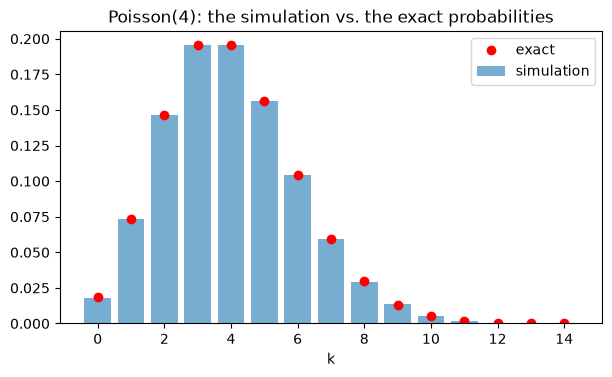

In [14]:
xs = [poisson(lam) for _ in range(n)]
m = sum(xs) / n
v = sum((x - m) ** 2 for x in xs) / (n - 1)
print(f"expectation {m:.3f}, variance {v:.3f}  (both should be {lam}; for the Poisson distribution they are equal)")

kmax = 15
counts = [xs.count(k) / n for k in range(kmax)]
exact_pmf = [lam ** k * math.exp(-lam) / math.factorial(k) for k in range(kmax)]

plt.figure(figsize=(7, 3.8))
plt.bar(range(kmax), counts, alpha=0.6, label="simulation")
plt.plot(range(kmax), exact_pmf, "ro", label="exact")
plt.xlabel("k")
plt.title(f"Poisson({lam:g}): the simulation vs. the exact probabilities")
plt.legend()
plt.show()

### The cost

The mean number of uniform numbers used is $\lambda + 1$ (the product falls by a factor of $e^{-1}$
per number), so the generation is **linear in $\lambda$**. For large $\lambda$ (hundreds) the
algorithm is slow, and on top of that $e^{-\lambda}$ **underflows**: from $\lambda \gtrsim 745$ on it
is exactly $0$ in the computer. The product version then returns nonsense (values around 700–800
regardless of $\lambda$) and the inverse version with the recurrence below **loops forever** (already
at $\lambda = 800$). For large $\lambda$ other methods are used (for instance the normal
approximation or the rejection method).

### An alternative: the basic algorithm with a recurrence

The Poisson distribution can also be generated with the basic algorithm from section 1; we just do
not compute the values $p_k$ in advance but **on the fly** from the recurrence
$p_{k+1} = p_k\,\lambda/(k+1)$:

In [15]:
def poisson_inverse(lam):
    '''The basic algorithm with the recurrence p_{k+1} = p_k * lam / (k + 1).'''
    u = random.random()
    k = 0
    pk = math.exp(-lam)
    total = pk
    while u >= total:
        k += 1
        pk *= lam / k
        total += pk
    return k


m, se = estimate(lambda: poisson_inverse(lam), n)
check("E X (poisson, inverse)", m, se, lam)

t0 = time.perf_counter()
estimate(lambda: poisson(lam), n)
t1 = time.perf_counter()
estimate(lambda: poisson_inverse(lam), n)
t2 = time.perf_counter()
print(f"time per draw: product of numbers {(t1 - t0) / n * 1e6:.2f} us,  inverse with recurrence {(t2 - t1) / n * 1e6:.2f} us")

E X (poisson, inverse): 3.99934 +- 0.00447  (exact 4.00000)


time per draw: product of numbers 0.38 us,  inverse with recurrence 0.40 us


Both methods give the same distribution. The inverse variant consumes **one** uniform number per
draw (the product version needs $\lambda + 1$ on average), which is handy when the generator is
expensive or when we need reproducibility.

## 6. The geometric distribution

The number of "failures" before the first "success" in independent trials with success probability
$p$ has $P(G = k) = (1-p)^k p$. The distribution function $P(G \le k) = 1 - (1-p)^{k+1}$ can be
inverted **in closed form**, so we need no loop at all:

$$G = \left\lfloor \frac{\ln \gamma}{\ln(1-p)} \right\rfloor.$$

> We use this formula in **exercise 9**: in the insurance model it lets us skip the days without a
> claim, so instead of $N$ draws we make only as many as there are claims.

(This is exactly the formula we used in exercise 2 to skip the intervals without a claim.)

In [16]:
def geometric(p):
    '''The number of failures before the first success; 1 - γ is uniform too, and never 0.'''
    return int(math.log(1.0 - random.random()) / math.log(1.0 - p))


pp = 0.2
m, se = estimate(lambda: geometric(pp), n)
check("E G", m, se, (1 - pp) / pp)

m, se = estimate(lambda: float(geometric(pp) == 3), n)
check("P(G = 3)", m, se, (1 - pp) ** 3 * pp)

E G: 4.00781 +- 0.01005  (exact 4.00000)


P(G = 3): 0.10158 +- 0.00068  (exact 0.10240)


## 7. An alternative: NumPy

NumPy has ready-made generators for all of these distributions and can generate a whole array at
once.

In [17]:
try:
    import numpy as np

    rng = np.random.default_rng(1)
    N = 1_000_000

    t0 = time.perf_counter()
    x1 = rng.choice(len(p), size=N, p=p)                 # the discrete distribution from section 1
    x2 = rng.poisson(lam, size=N)
    x3 = rng.geometric(pp, size=N) - 1                   # NumPy counts trials, not failures
    t = time.perf_counter() - t0

    print(f"E X (choice) = {x1.mean():.4f}   (exactly {exact_mean:.4f})")
    print(f"E X (poisson) = {x2.mean():.4f}, variance = {x2.var():.4f}   (both {lam})")
    print(f"E G (geometric) = {x3.mean():.4f}   (exactly {(1 - pp) / pp:.4f})")
    print(f"{3 * N:,} samples in {t:.2f} s".replace(",", " "))
except ModuleNotFoundError:
    print("NumPy is not installed, run:  uv sync")

E X (choice) = 2.7999   (exactly 2.8000)
E X (poisson) = 4.0001, variance = 3.9974   (both 4.0)
E G (geometric) = 3.9941   (exactly 4.0000)
3 000 000 samples in 0.08 s


Watch out for the difference in conventions: `numpy.random.Generator.geometric` counts **trials
including the successful one** (values $1, 2, \dots$), while we count **failures** ($0, 1, \dots$).
That is why we subtract one. Differences like this between libraries are a frequent source of bugs.

## Summary

| Concept | What to remember |
|---------|------------------|
| The basic algorithm | $S = \gamma$, subtract $p_k$ while $S \ge 0$; return $k$ (the inverse transform) |
| The cost | $E[\text{steps}] = \sum (k+1)p_k$; sort the values **descending** by $p_k$ |
| Bisection | precompute the cumulative sums in $O(n)$, then $O(\log n)$ per draw; independent of the order |
| Choosing a method | strongly uneven $p_k$: sorted linear; otherwise bisection |
| Poisson | multiply $\gamma_i$ until the product is $< e^{-\lambda}$; the result is the count of numbers **minus 1**; cost $\sim\lambda$ |
| Geometric | $\lfloor \ln \gamma / \ln(1-p)\rfloor$, a closed formula with no loop |
| Testing | verify every generator with the expectation and the variance; an off-by-one is harder to find than it looks |

### Try it yourself

1. Using `linear` and `make_bisect`, generate the **sum of two dice** (values $2, \dots, 12$ with
   probabilities $1/36, 2/36, \dots, 6/36, \dots, 1/36$). Verify the expectation $7$ with `check`.
2. Find out from which $\lambda$ on `poisson_inverse` is slower than `poisson`, or the other way
   round. Is it a $\lambda$ near $1$, or near $10$?
3. Generate the **binomial** distribution $\operatorname{Bi}(n, p)$ in three ways: as a sum of $n$
   Bernoulli variables, with the basic algorithm using the recurrence
   $p_{k+1} = p_k\,\frac{n-k}{k+1}\,\frac{p}{1-p}$, and with `rng.binomial`. How many uniform numbers
   does each method consume?